## 1. Implement Gaussian and Laplacian image pyramids to analyze vehicles of different sizes in a traffic image.

In [5]:
import cv2
import matplotlib.pyplot as plt

# Step 1: Read the traffic image
img = cv2.imread("traffic.jpg")

# Check whether the image was loaded
if img is None:
    print("Error: Image not found!")
    exit()

# Convert BGR to RGB for correct display in Matplotlib
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

In [6]:
# Step 2: Create the Gaussian pyramid
gaussian = [img]

for i in range(3):
    img = cv2.pyrDown(img)
    gaussian.append(img)

# Step 3: Create the Laplacian pyramid
laplacian = []

for i in range(len(gaussian) - 1):
    # Get the current image
    current = gaussian[i]

    # Get the next smaller image
    smaller = gaussian[i + 1]

    # Expand the smaller image to the current image size
    expanded = cv2.pyrUp(
        smaller,
        dstsize=(current.shape[1], current.shape[0])
    )

    # Subtract to obtain image details
    lap = cv2.subtract(current, expanded)

    laplacian.append(lap)


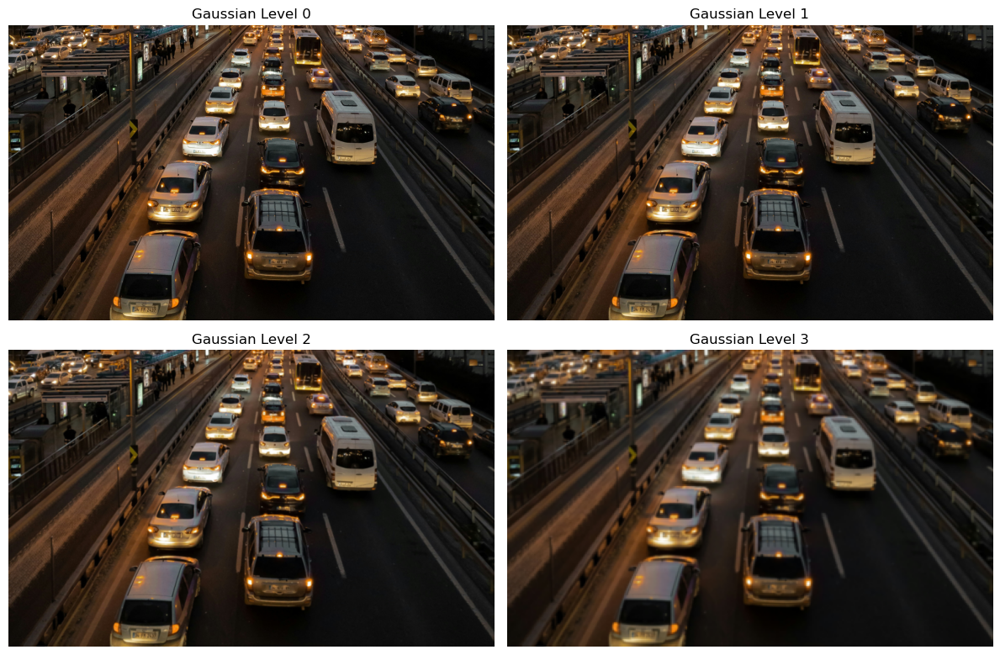

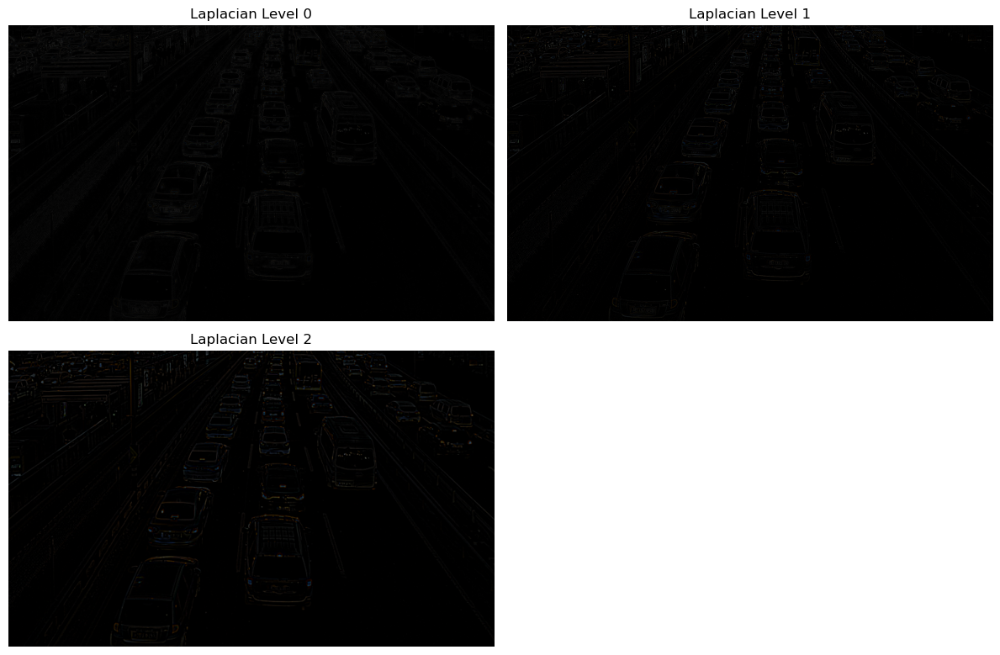

In [7]:
# Step 4: Display the Gaussian pyramid
plt.figure(figsize=(12, 8))

for i, image in enumerate(gaussian):
    plt.subplot(2, 2, i + 1)
    plt.imshow(image)
    plt.title("Gaussian Level " + str(i))
    plt.axis("off")

plt.tight_layout()
plt.show()

# Step 5: Display the Laplacian pyramid
plt.figure(figsize=(12, 8))

for i, image in enumerate(laplacian):
    plt.subplot(2, 2, i + 1)
    plt.imshow(image)
    plt.title("Laplacian Level " + str(i))
    plt.axis("off")

plt.tight_layout()
plt.show()


## 2. Implement an image-pyramid-based approach to detect faces appearing at different scales in a photograph.

In [34]:
import cv2
import matplotlib.pyplot as plt

# Step 1: Load the photograph
img = cv2.imread("people2.jpg")

if img is None:
    print("Error: Image not found!")
    exit()

# Convert image to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

In [35]:
# Step 2: Load the pre-trained face detector
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades +
    "haarcascade_frontalface_default.xml"
)

# Step 3: Create a copy for drawing rectangles
result = img.copy()

# Step 4: Set the initial image scale
scale = 1.0

# Step 5: Detect faces at different image scales
while True:

    # Resize the original grayscale image
    resized = cv2.resize(gray,None,fx=scale,fy=scale)

    # Detect faces in the resized image
    faces = face_cascade.detectMultiScale(resized,scaleFactor=1.1,minNeighbors=15,minSize=(30, 30))

    # Draw rectangles on the original image
    for (x, y, w, h) in faces:

        # Convert coordinates to original image size
        x = int(x / scale)
        y = int(y / scale)
        w = int(w / scale)
        h = int(h / scale)

        cv2.rectangle(result,(x, y),(x + w, y + h),(0, 255, 0),2)

    # Stop when the image becomes too small
    if resized.shape[1] < 100 or resized.shape[0] < 100:
        break

    # Reduce the image size for the next level
    scale = scale * 0.8

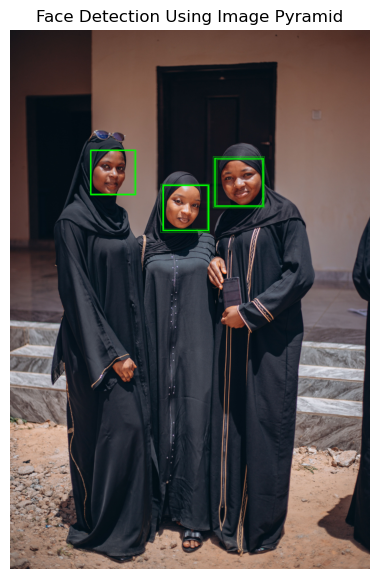

In [36]:
# Step 6: Display the final result
result = cv2.cvtColor(result, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 7))
plt.imshow(result)
plt.title("Face Detection Using Image Pyramid")
plt.axis("off")
plt.show()

## 3. Implement multi-scale image processing to detect a person appearing at different distances from a surveillance camera.

In [30]:
import cv2
import matplotlib.pyplot as plt

# Step 1: Load the surveillance image
img = cv2.imread("crowd.jpg")

if img is None:
    print("Error: Image not found!")
    exit()

# Step 2: Create a copy for displaying results
result = img.copy()

In [ ]:
# Step 3: Load the pre-trained HOG person detector
hog = cv2.HOGDescriptor()

hog.setSVMDetector(
    cv2.HOGDescriptor_getDefaultPeopleDetector()
)

# Step 4: Set image scale
scale = 1.0

# Step 5: Detect people at different scales
while True:

    # Resize the image
    resized = cv2.resize(img,None,fx=scale,fy=scale)

    # Detect people in the resized image
    boxes, weights = hog.detectMultiScale(resized,winStride=(8,8),padding=(8,8),scale=1.05)

    # Step 6: Convert coordinates to original image size
    for (x, y, w, h) in boxes:

        x = int(x / scale)
        y = int(y / scale)
        w = int(w / scale)
        h = int(h / scale)

        # Draw a rectangle around the person
        cv2.rectangle(result,(x, y),(x + w, y + h),(0, 255, 0),2)

        # Stop when the resized image becomes too small
        if resized.shape[1] < 160 or resized.shape[0] < 160:
            break

        # Reduce the image size for the next level
        scale = scale * 0.8

In [ ]:
# Step 7: Display the final result
result = cv2.cvtColor(result,cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 7))
plt.imshow(result)
plt.title("Multi-Scale Person Detection")
plt.axis("off")
plt.show()

## 4. Generate different-resolution versions of a scanned document using Gaussian pyramids and analyze the effect of resolution on character readability.

In [1]:
import cv2
import matplotlib.pyplot as plt

# Step 1: Load the scanned document
img = cv2.imread("document.png")

if img is None:
    print("Error: Image not found!")
    exit()

# Convert the image to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

In [7]:
# Step 2: Create the Gaussian pyramid
pyramid = [gray]

for i in range(4):
    # Reduce the image size by half
    gray = cv2.pyrDown(gray)
    pyramid.append(gray)

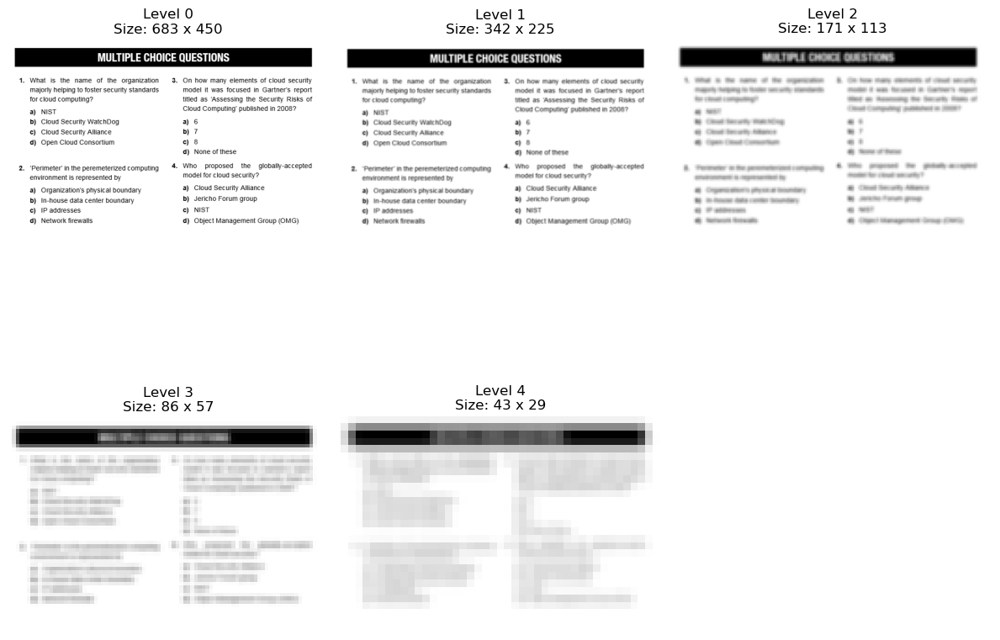

In [8]:
# Step 3: Display all resolution levels
plt.figure(figsize=(12, 10))

for i, image in enumerate(pyramid):
    plt.subplot(2, 3, i + 1)
    plt.imshow(image, cmap="gray")
    # Display image size
    height, width = image.shape
    
    plt.title("Level " + str(i) + "\nSize: " + str(width) + " x " + str(height))
    plt.axis("off")

plt.tight_layout()
plt.show()

In [11]:
# # Step 4: Save each resolution version
# for i, image in enumerate(pyramid):
#     filename = "document_level_" + str(i) + ".jpg"
#     cv2.imwrite(filename, image)

# print("All resolution images saved successfully!")

## 5. Implement Gaussian derivative filters to detect road boundaries and lane markings in a road image

In [5]:
import cv2
import matplotlib.pyplot as plt

# Step 1: Read the road image
img = cv2.imread("road.jpg")

if img is None:
    print("Error: Image not found!")
    exit()

# Step 2: Convert image to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

In [6]:
# Step 3: Apply Gaussian blur to remove noise
blur = cv2.GaussianBlur(gray, (5, 5), 0)

# Step 4: Apply Gaussian derivative filters using Sobel
# Detect horizontal brightness changes (vertical edges)
sobel_x = cv2.Sobel(blur, cv2.CV_64F, 1, 0, ksize=3)

# Detect vertical brightness changes (horizontal edges)
sobel_y = cv2.Sobel(blur, cv2.CV_64F, 0, 1, ksize=3)

# Step 5: Combine the edge information
edges = cv2.magnitude(sobel_x, sobel_y)

# Convert edges to 8-bit image
edges = cv2.convertScaleAbs(edges)

# Step 6: Apply thresholding
_, binary = cv2.threshold(edges, 50, 255, cv2.THRESH_BINARY)

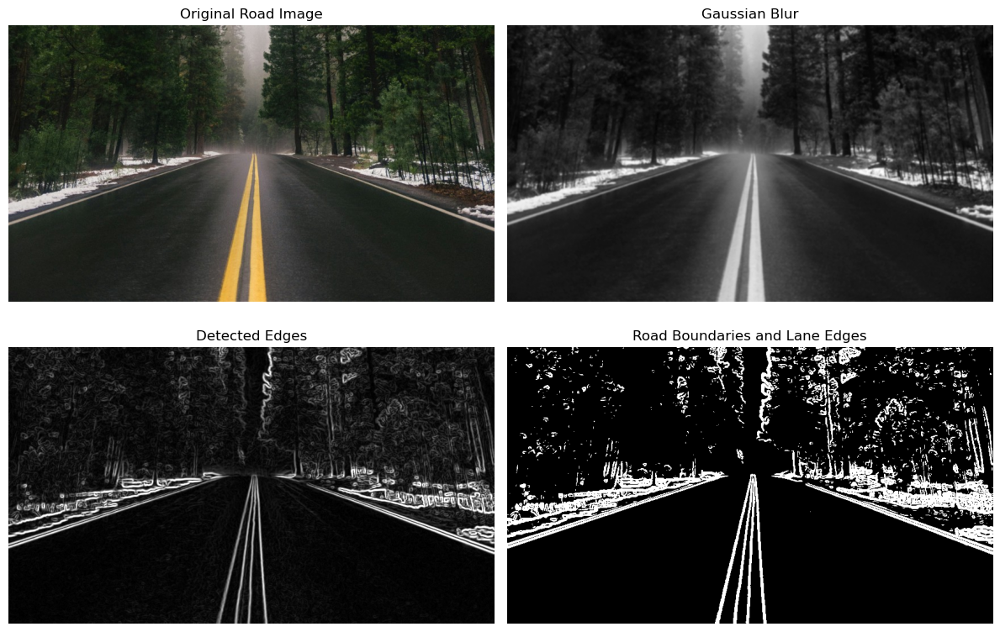

In [7]:
# Step 7: Display results
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Road Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(blur, cmap="gray")
plt.title("Gaussian Blur")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(edges, cmap="gray")
plt.title("Detected Edges")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(binary, cmap="gray")
plt.title("Road Boundaries and Lane Edges")
plt.axis("off")

plt.tight_layout()
plt.show()

## 6. Implement first-order and second-order Gaussian derivative filters to detect boundaries and defects on a manufactured product.

In [16]:
import cv2
import matplotlib.pyplot as plt

# Step 1: Load the product image
img = cv2.imread("product3.jpg")

if img is None:
    print("Error: Image not found!")
    exit()

# Step 2: Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

In [17]:
# Step 3: Apply Gaussian blur
blur = cv2.GaussianBlur(gray, (5, 5), 0)

# Step 4: First-order derivative using Sobel
first_order = cv2.Sobel(blur, cv2.CV_64F, 1, 0, ksize=3)
first_order = cv2.convertScaleAbs(first_order)

# Step 5: Second-order derivative using Laplacian
second_order = cv2.Laplacian(blur, cv2.CV_64F, ksize=3)
second_order = cv2.convertScaleAbs(second_order)

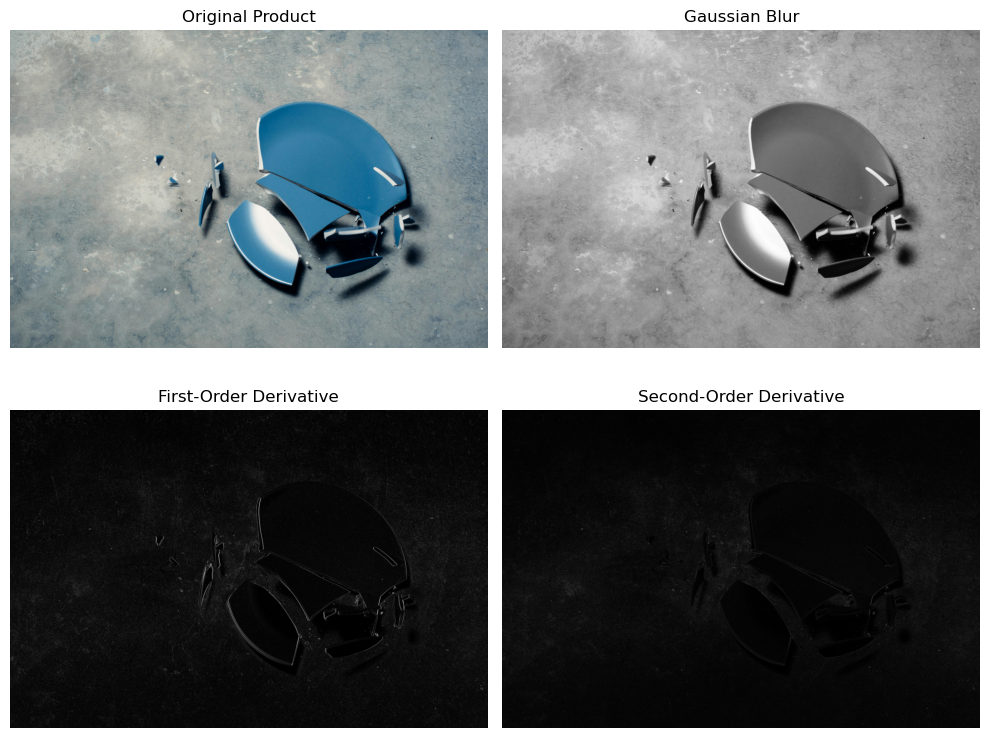

In [18]:
# Step 6: Display all images
plt.figure(figsize=(10, 8))

plt.subplot(2, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Product")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(blur, cmap="gray")
plt.title("Gaussian Blur")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(first_order, cmap="gray")
plt.title("First-Order Derivative")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(second_order, cmap="gray")
plt.title("Second-Order Derivative")
plt.axis("off")

plt.tight_layout()
plt.show()

## 7. Implement Gabor filters with different orientations and frequencies to identify defective regions in a fabric image.

In [23]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Load the fabric image
img = cv2.imread("fabric.jpg")

if img is None:
    print("Error: Image not found!")
    exit()

# Convert image to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

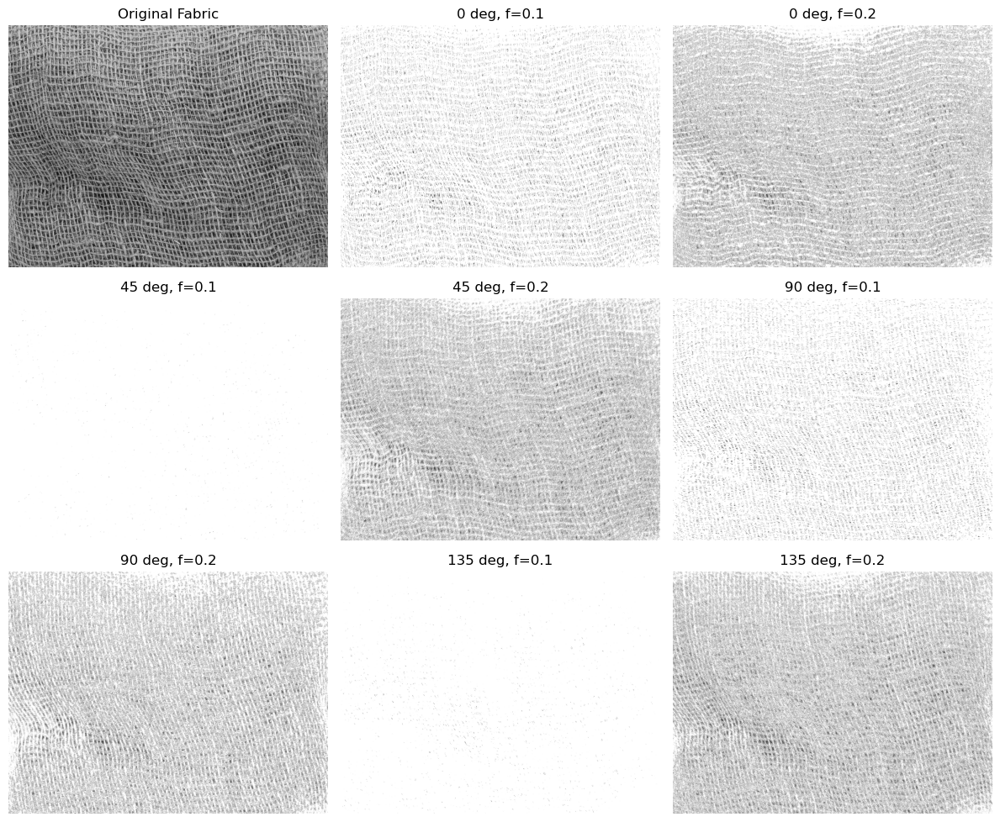

In [24]:
# Step 2: Create Gabor filters
orientations = [0, 45, 90, 135]
frequencies = [0.1, 0.2]

# Display original image
plt.figure(figsize=(12, 10))

plt.subplot(3, 3, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original Fabric")
plt.axis("off")

# Step 3: Apply filters
plot_no = 2

for angle in orientations:
    for freq in frequencies:

        # Convert angle to radians
        theta = np.deg2rad(angle)

        # Create Gabor kernel
        kernel = cv2.getGaborKernel((10,10),4.0,theta,1.0 / freq,0.5,0,ktype=cv2.CV_32F)

        # Apply filter to fabric image
        filtered = cv2.filter2D(gray, cv2.CV_32F, kernel)

        # Convert result to displayable image
        filtered = cv2.convertScaleAbs(filtered)

        # Display filtered image
        plt.subplot(3, 3, plot_no)
        plt.imshow(filtered, cmap="gray")
        plt.title(str(angle) + " deg, f=" + str(freq))
        plt.axis("off")

        plot_no += 1

        # Stop after filling 9 plots
        if plot_no > 9:
            break

    if plot_no > 9:
        break

plt.tight_layout()
plt.show()

## 8. Apply Gabor filters to enhance fingerprint ridge patterns and visualize the resulting texture information.

In [49]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Load fingerprint image
img = cv2.imread("fingerprint.png")

if img is None:
    print("Error: Image not found!")
    exit()

# Step 2: Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

In [67]:
# Step 3: Resize image
gray = cv2.resize(gray, (300, 300))

# Step 4: Apply Gaussian blur
blur = cv2.GaussianBlur(gray, (3, 3), 0)

# Step 5: Create a Gabor filter
theta = np.deg2rad(45)  # Ridge direction
frequency = 0.1

kernel = cv2.getGaborKernel(
    (21,21),       # Kernel size
    4.0,            # Sigma
    theta,          # Orientation
    1 / frequency,  # Wavelength
    5,            # Aspect ratio
    0,              # Phase offset
    ktype=cv2.CV_32F
)

# Step 6: Apply Gabor filter
filtered = cv2.filter2D(blur, cv2.CV_32F, kernel)

# Step 7: Normalize result for display
filtered = cv2.normalize(filtered, None, 0, 255, cv2.NORM_MINMAX)
filtered = filtered.astype(np.uint8)

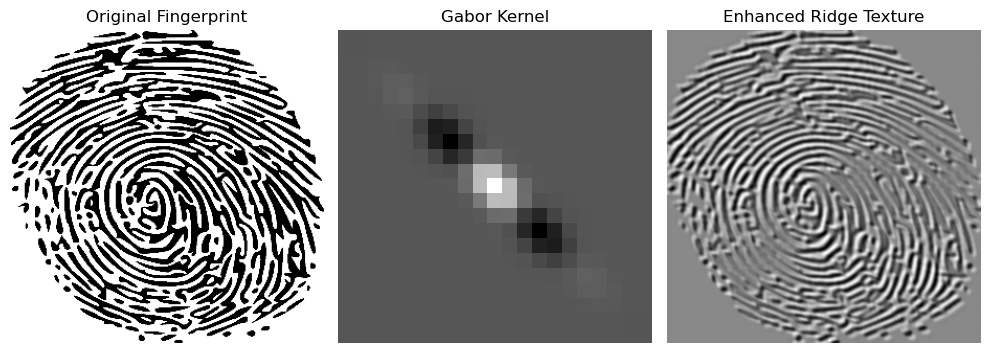

In [68]:
# Step 8: Display images
plt.figure(figsize=(10, 5))

plt.subplot(1, 3, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original Fingerprint")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(kernel, cmap="gray")
plt.title("Gabor Kernel")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(filtered, cmap="gray")
plt.title("Enhanced Ridge Texture")
plt.axis("off")

plt.tight_layout()
plt.show()

## 9. Implement Gabor-filter-based texture analysis to distinguish between smooth and rough or cracked road surfaces

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Load road image
img = cv2.imread("road3.jpg")

if img is None:
    print("Error: Image not found!")
    exit()

# Step 2: Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

In [2]:
# Step 3: Resize image
gray = cv2.resize(gray, (400, 300))

# Step 4: Create Gabor filter settings
orientations = [0, 45, 90, 135]
responses = []

# Step 5: Apply Gabor filters
for angle in orientations:

    theta = np.deg2rad(angle)

    kernel = cv2.getGaborKernel(
        (10,10),  # Kernel size
        4.0,       # Sigma
        theta,     # Orientation
        10.0,      # Wavelength
        0.5,       # Gamma
        0,         # Phase
        ktype=cv2.CV_32F
    )

    # Apply filter
    filtered = cv2.filter2D(gray, cv2.CV_32F, kernel)

    # Convert response to absolute values
    filtered = np.abs(filtered)
    
    responses.append(filtered)

# Step 6: Combine all filter responses
texture = np.mean(responses, axis=0)

# Step 7: Calculate texture score
score = np.mean(texture)

print("Texture Score:", round(float(score), 2))

Texture Score: 2074.75


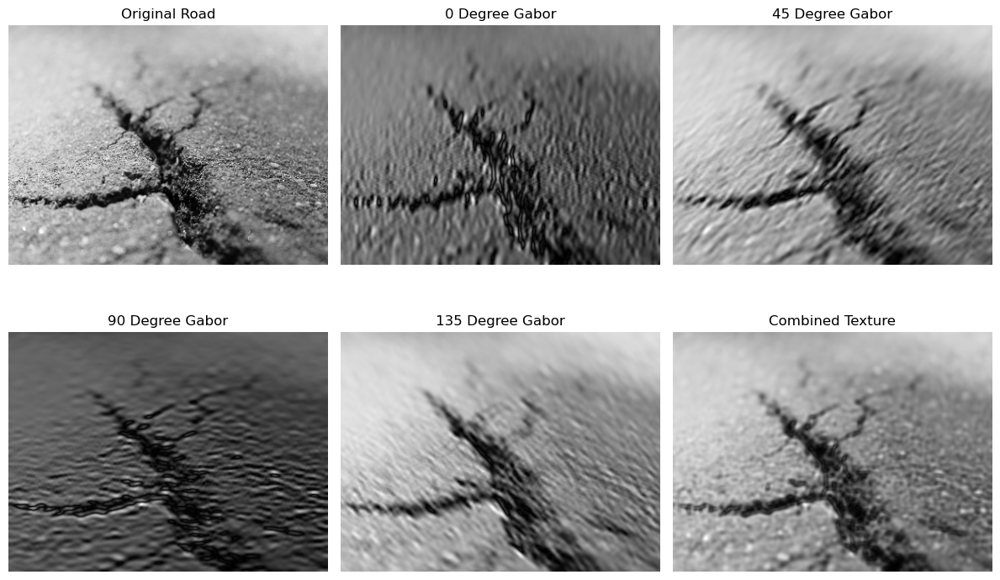

In [3]:
# Step 8: Display results
plt.figure(figsize=(12, 8))

plt.subplot(2, 3, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original Road")
plt.axis("off")

for i in range(4):
    plt.subplot(2, 3, i + 2)
    plt.imshow(responses[i], cmap="gray")
    plt.title(str(orientations[i]) + " Degree Gabor")
    plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(texture, cmap="gray")
plt.title("Combined Texture")
plt.axis("off")

plt.tight_layout()
plt.show()

## 10. Extract texture features using Gabor filters and classify images of different types of wood.


In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [5]:
# Function to extract Gabor texture features
def extract_features(image_path):

    # Read image
    img = cv2.imread(image_path)

    if img is None:
        print("Image not found:", image_path)
        return None

    # Convert to grayscale
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Resize image
    gray = cv2.resize(gray, (200, 200))

    features = []

    # Apply Gabor filters at different angles
    for angle in [0, 45, 90, 135]:

        theta = np.deg2rad(angle)

        kernel = cv2.getGaborKernel((21, 21),4.0,theta,10.0,0.5,0,ktype=cv2.CV_32F)

        # Apply filter
        filtered = cv2.filter2D(gray, cv2.CV_32F, kernel)

        # Calculate texture features
        features.append(np.mean(np.abs(filtered)))
        features.append(np.std(filtered))

    return features

In [6]:
# Step 1: List wood images
images = ["wood1.jpg","wood2.jpg","wood3.jpg"]

# Step 2: Extract and display features
for image_path in images:

    features = extract_features(image_path)

    if features is None:
        continue

    print("\nImage:", image_path)
    print("Gabor Features:", np.round(features, 2))

    # Step 3: Simple rule-based classification
    texture_score = np.mean(features[::2])

    print("Texture Score:", np.round(texture_score, 2))

    if texture_score < 500:
        wood_type = "Class A"
    elif texture_score < 1500:
        wood_type = "Class B"
    else:
        wood_type = "Class C"

    print("Predicted Wood Type:", wood_type)



Image: wood1.jpg
Gabor Features: [1486.25 1729.62 1522.81  556.86  777.67  416.99 1520.56  555.07]
Texture Score: 1326.82
Predicted Wood Type: Class B

Image: wood2.jpg
Gabor Features: [ 957.38  639.82 1785.58  544.13  892.92  356.19 1763.92  486.7 ]
Texture Score: 1349.95
Predicted Wood Type: Class B

Image: wood3.jpg
Gabor Features: [ 457.91  365.21  892.23  642.76  852.56 1028.    852.23  485.67]
Texture Score: 763.73
Predicted Wood Type: Class B


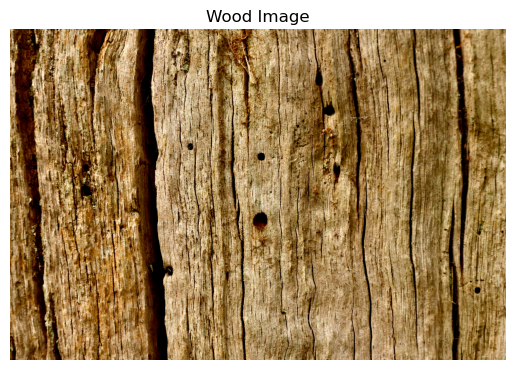

In [7]:
# Step 4: Display one example image
img = cv2.imread(images[0])

if img is not None:
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.imshow(img)
    plt.title("Wood Image")
    plt.axis("off")
    plt.show()

## 11. Use Gabor filters to distinguish between healthy and diseased regions of a plant leaf based on texture characteristics.

In [32]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# 1. Load the leaf image in grayscale
# Replace 'leaf.jpg' with the path to your image
image = cv2.imread('leaf.jpg', cv2.IMREAD_GRAYSCALE)

if image is None:
  print('Error: Image not found. Please check the file path.')
else:
  # Resize for consistent processing
  image = cv2.resize(image, (400, 400))

  # 2. Define Gabor filter parameters
  ksize = 40  # Size of the filter kernel
  sigma = 4.0  # Standard deviation of the Gaussian envelope
  theta = np.pi / 4  # Orientation angle (e.g., 45 degrees)
  lambd = 10.0  # Wavelength of the sinusoidal factor
  gamma = 2  # Spatial aspect ratio (ellipticity)
  psi = 0.0  # Phase offset

  # Create the Gabor kernel
  gabor_kernel = cv2.getGaborKernel(
      (ksize, ksize), sigma, theta, lambd, gamma, psi, ktype=cv2.CV_32F
  )

  # 3. Filter the image to extract texture features
  filtered_image = cv2.filter2D(image, cv2.CV_8UC3, gabor_kernel)

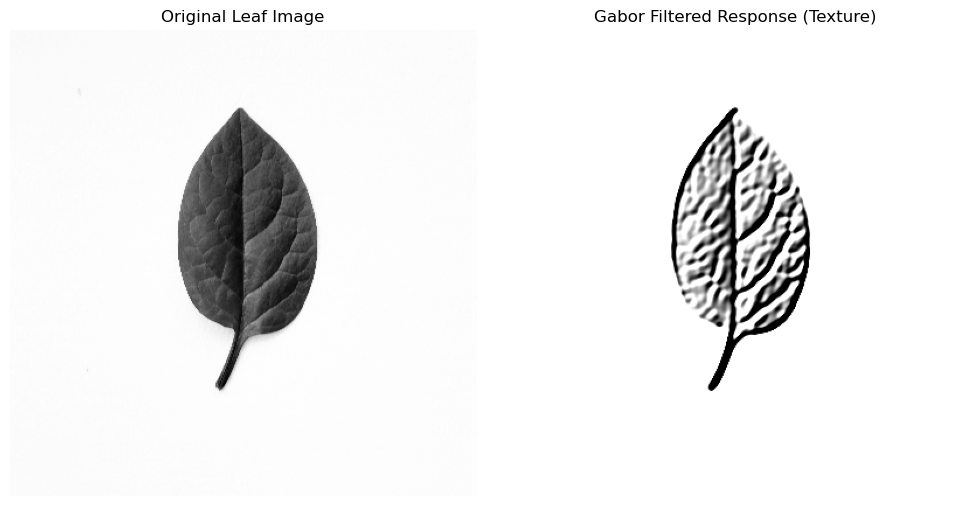

In [33]:
  # 4. Visualize the original and filtered textures using Matplotlib
  plt.figure(figsize=(10, 5))

  plt.subplot(1, 2, 1)
  plt.imshow(image, cmap='gray')
  plt.title('Original Leaf Image')
  plt.axis('off')

  plt.subplot(1, 2, 2)
  plt.imshow(filtered_image, cmap='gray')
  plt.title('Gabor Filtered Response (Texture)')
  plt.axis('off')

  plt.tight_layout()
  plt.show()

## 12. Apply Gabor filters to identify and differentiate surface textures in images of tiles, metal, or other manufactured materials.

Texture Score: 244.39


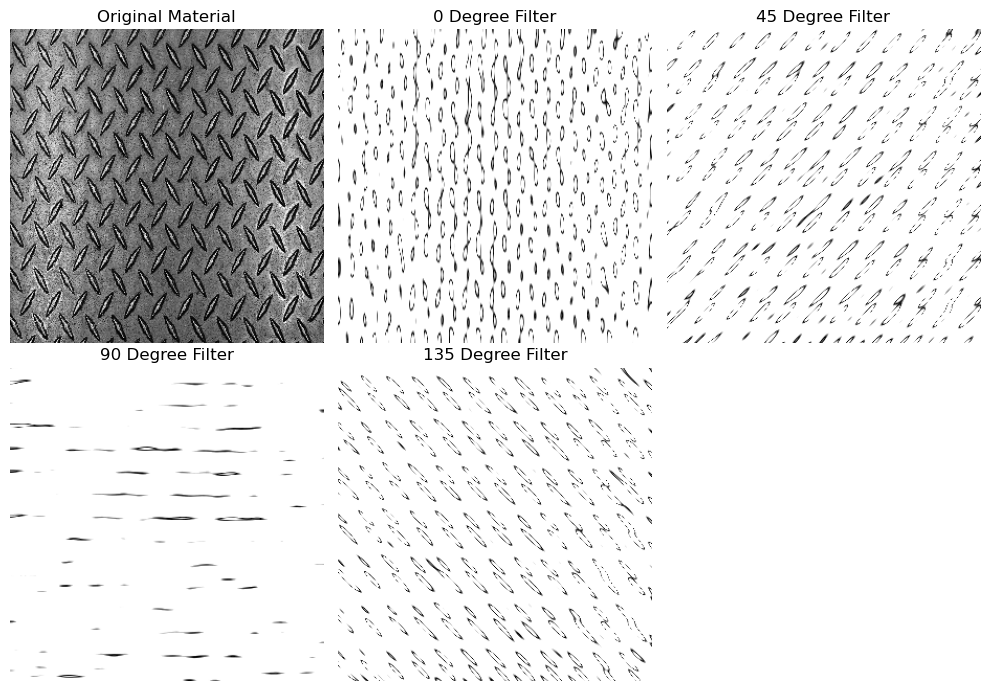

In [7]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Read the material image
img = cv2.imread("metal.jpg")

if img is None:
    print("Error: Image not found!")
    exit()

# Step 2: Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Step 3: Resize image
gray = cv2.resize(gray, (300, 300))

# Step 4: Apply Gabor filters at different angles
angles = [0, 45, 90, 135]
responses = []

for angle in angles:

    # Convert angle to radians
    theta = np.deg2rad(angle)

    # Create Gabor filter
    kernel = cv2.getGaborKernel((40,40),4.0,theta,10.0,0.5,0,ktype=cv2.CV_32F)

    # Apply filter
    filtered = cv2.filter2D(gray, cv2.CV_32F, kernel)

    # Convert response to visible image
    filtered = cv2.convertScaleAbs(filtered)

    responses.append(filtered)

# Step 5: Display results
plt.figure(figsize=(10, 7))

plt.subplot(2, 3, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original Material")
plt.axis("off")

for i in range(4):
    plt.subplot(2, 3, i + 2)
    plt.imshow(responses[i], cmap="gray")
    plt.title(str(angles[i]) + " Degree Filter")
    plt.axis("off")

# Step 6: Calculate texture score
score = np.mean(responses)

print("Texture Score:", round(float(score), 2))

plt.tight_layout()
plt.show()

## 13. Implement two-dimensional Discrete Wavelet Transform (DWT) for image compression and reconstruct the image using selected wavelet coefficients.


In [15]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pywt

# 1. Load image in grayscale and resize for clean wavelet levels
# Replace 'image.jpg' with your target image path
image = cv2.imread('image.jpg', cv2.IMREAD_GRAYSCALE)
image = cv2.resize(image, (512, 512))

In [16]:
# 2. Apply 2D Discrete Wavelet Transform (DWT) using the 'haar' wavelet
# Returns approximation (LL) and details (LH: horizontal, HL: vertical, HH: diagonal)
coeffs2 = pywt.dwt2(image, 'haar')
LL, (LH, HL, HH) = coeffs2

# 3. Compress by thresholding (zeroing out weak coefficients to save space)
threshold = 25
LH_thresh = pywt.threshold(LH, threshold, mode='soft')
HL_thresh = pywt.threshold(HL, threshold, mode='soft')
HH_thresh = pywt.threshold(HH, threshold, mode='soft')

# Combine the thresholded coefficients back
coeffs_compressed = (LL, (LH_thresh, HL_thresh, HH_thresh))

# 4. Reconstruct the image from the selected/compressed coefficients
reconstructed_image = pywt.idwt2(coeffs_compressed, 'haar')

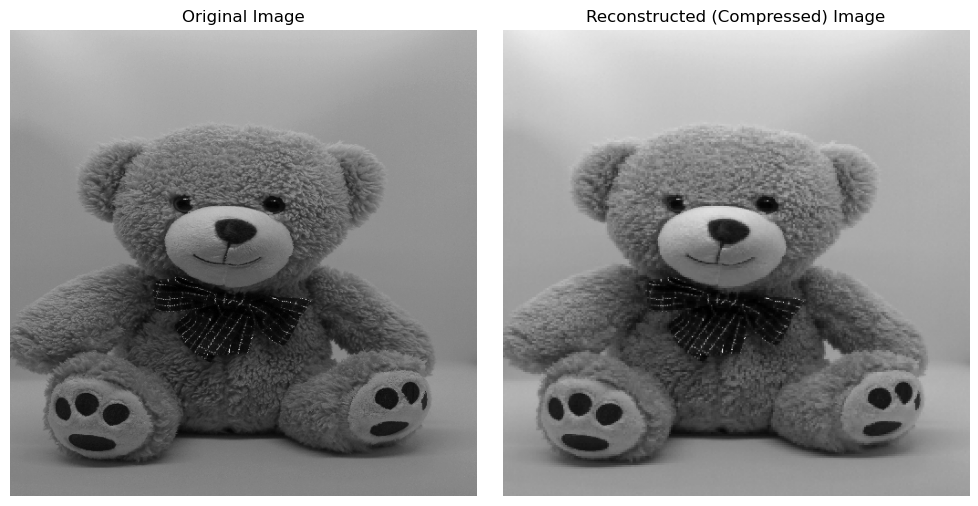

In [17]:
# 5. Visualize Original vs. Reconstructed Compressed Image
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(reconstructed_image, cmap='gray')
plt.title('Reconstructed (Compressed) Image')
plt.axis('off')

plt.tight_layout()
plt.show()

## 14. Implement DWT-based image denoising on a noisy medical image and compare the original, noisy, and denoised images.

In [29]:
import cv2
import pywt
import numpy as np
import matplotlib.pyplot as plt

# Read image
img = cv2.imread("medical.jpg",0)

if img is None:
    print("Image not found!")
    exit()

In [33]:
# Add stronger Gaussian noise
np.random.seed(10)
noise = np.random.normal(0, 25, img.shape)
noisy = np.clip(img.astype(float) + noise, 0, 255).astype(np.uint8)

# Apply DWT
LL, (LH, HL, HH) = pywt.dwt2(noisy, "haar")

# Remove noise using thresholding
LH = pywt.threshold(LH, 35, mode="soft")
HL = pywt.threshold(HL, 35, mode="soft")
HH = pywt.threshold(HH, 35, mode="soft")

# Reconstruct image
denoised = pywt.idwt2((LL, (LH, HL, HH)), "haar")
denoised = np.clip(denoised, 0, 255).astype(np.uint8)

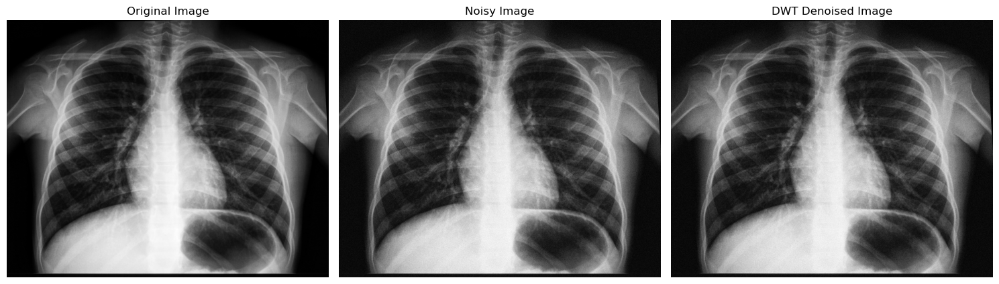

In [34]:
# Display images
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(noisy, cmap="gray", vmin=0, vmax=255)
plt.title("Noisy Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(denoised, cmap="gray", vmin=0, vmax=255)
plt.title("DWT Denoised Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [35]:
# Make sure the original/noisy images match the denoised image's shape
h, w = denoised.shape[:2]
img_resized = cv2.resize(img, (w, h))
noisy_resized = cv2.resize(noisy, (w, h))

# Now calculate the standard deviation of the differences safely
print('Noisy image standard deviation:',np.std(noisy_resized.astype(float) - img_resized.astype(float)))
print('Denoised image standard deviation:',np.std(denoised.astype(float) - img_resized.astype(float)))

Noisy image standard deviation: 15.095075925789017
Denoised image standard deviation: 12.801370436482742


## 15. Apply DWT-based denoising to an old or degraded photograph while preserving important image details.

In [46]:
import cv2
import pywt
import numpy as np
import matplotlib.pyplot as plt

# Read old photograph
img = cv2.imread("old_photo.jpg", 0)

if img is None:
    print("Image not found!")
    exit()

In [53]:
# Add noise to simulate a degraded photograph
noise = np.random.normal(0,25, img.shape)
noisy = np.clip(img.astype(float) + noise, 0, 255).astype(np.uint8)

# Apply DWT
LL, (LH, HL, HH) = pywt.dwt2(noisy, "haar")

# Apply soft thresholding to remove noise
LH = pywt.threshold(LH, 10, mode="soft")
HL = pywt.threshold(HL, 10, mode="soft")
HH = pywt.threshold(HH, 10, mode="soft")

# Reconstruct image
denoised = pywt.idwt2((LL, (LH, HL, HH)), "haar")
denoised = np.clip(denoised, 0, 255).astype(np.uint8)

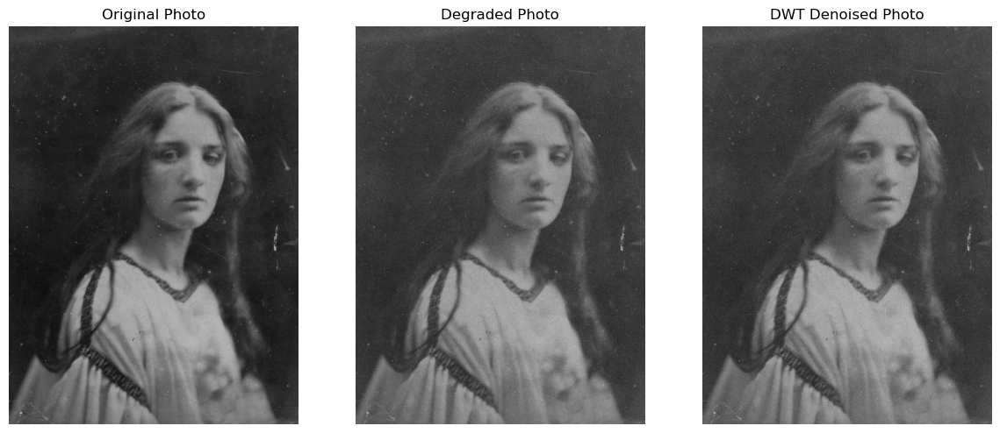

In [54]:
# Compare images
plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Photo")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(noisy, cmap="gray")
plt.title("Degraded Photo")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(denoised, cmap="gray")
plt.title("DWT Denoised Photo")
plt.axis("off")

plt.tight_layout()
plt.show()

## 16. Implement DWT-based digital watermarking by embedding a watermark into an image and recovering the embedded watermark.

In [5]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pywt

# 1. Load Host and Watermark images in grayscale
host = cv2.imread('image.jpg', cv2.IMREAD_GRAYSCALE)
watermark = cv2.imread('watermark.jpg', cv2.IMREAD_GRAYSCALE)

# Resize to required dimensions (watermark must be half the host dimensions for DWT)
host = cv2.resize(host, (512, 512))
watermark = cv2.resize(watermark, (256, 256))
_, watermark = cv2.threshold(watermark, 127, 1, cv2.THRESH_BINARY)

# 2. Apply Wavelet Transform to Host Image
LL, (LH, HL, HH) = pywt.dwt2(host, 'haar')

# 3. Embed Watermark into the HL frequency band
alpha = 20.0  # Strength of the watermark
HL_watermarked = HL + (alpha * watermark.astype(np.float32))

# 4. Reconstruct the Watermarked Image
watermarked_image = pywt.idwt2((LL, (LH, HL_watermarked, HH)), 'haar')
watermarked_image = np.clip(watermarked_image, 0, 255).astype(np.uint8)

# 5. Extract the Watermark back out
extracted = (HL_watermarked - HL) / alpha
extracted = np.clip(extracted * 255, 0, 255).astype(np.uint8)

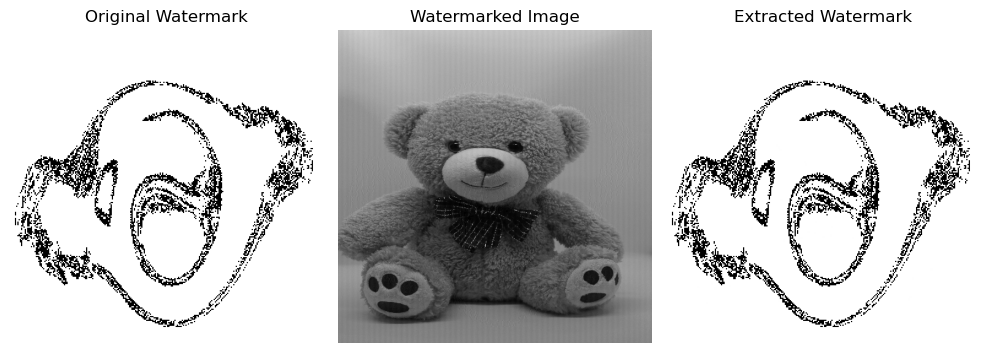

In [6]:
# 6. Show Results
plt.figure(figsize=(10, 4))

plt.subplot(1, 3, 1)
plt.imshow(watermark * 255, cmap='gray')
plt.title('Original Watermark')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(watermarked_image, cmap='gray')
plt.title('Watermarked Image')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(extracted, cmap='gray')
plt.title('Extracted Watermark')
plt.axis('off')

plt.tight_layout()
plt.show()

## 17. Analyze the quality of two images using their DWT coefficients and compare the amount of detail information present in each image.

In [9]:
import cv2
import pywt
import numpy as np
import matplotlib.pyplot as plt

# Read two images in grayscale
img1 = cv2.imread("product.jpg", 0)
img2 = cv2.imread("product2.jpg", 0)

if img1 is None or img2 is None:
    print("Image not found!")
    exit()

In [10]:
# Resize images to the same size
img2 = cv2.resize(img2, (img1.shape[1], img1.shape[0]))

# Apply DWT
LL1, (LH1, HL1, HH1) = pywt.dwt2(img1, "haar")
LL2, (LH2, HL2, HH2) = pywt.dwt2(img2, "haar")

# Calculate detail energy
energy1 = np.mean(LH1**2 + HL1**2 + HH1**2)
energy2 = np.mean(LH2**2 + HL2**2 + HH2**2)

print("Image 1 Detail Energy:", round(energy1, 2))
print("Image 2 Detail Energy:", round(energy2, 2))

Image 1 Detail Energy: 26.4
Image 2 Detail Energy: 47.24


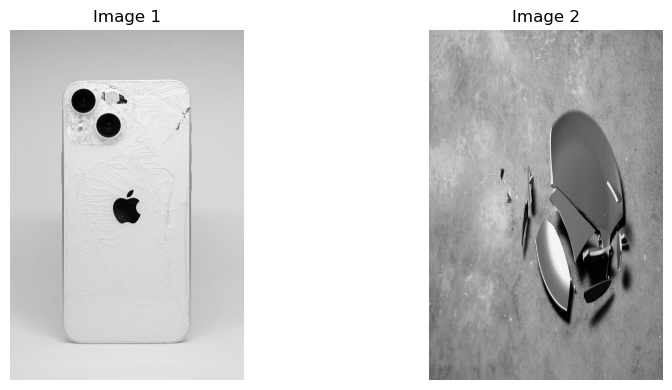

Image 2 contains more high-frequency detail energy.


In [11]:
# Display images
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(img1, cmap="gray")
plt.title("Image 1")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img2, cmap="gray")
plt.title("Image 2")
plt.axis("off")

plt.tight_layout()
plt.show()

# Compare detail information
if energy1 > energy2:
    print("Image 1 contains more high-frequency detail energy.")
elif energy2 > energy1:
    print("Image 2 contains more high-frequency detail energy.")
else:
    print("Both images have equal detail energy.")

## 18. Implement the Region Growing segmentation technique to segment a selected region from a medical image using suitable seed points.

In [21]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Load your image in grayscale
img = cv2.imread('med2.jpg', cv2.IMREAD_GRAYSCALE)

img = cv2.resize(img,(400,400))

In [30]:
# 2. Pick a seed point (X, Y) inside the region you want to segment
h, w = img.shape
seed = (200,200)
threshold = 30  # Brightness tolerance

# 3. Simple Region Growing
mask = np.zeros((h, w), dtype=np.uint8)
visited = np.zeros((h, w), dtype=bool)

seed_val = int(img[seed[1], seed[0]])
queue = [seed]

while queue:
    x, y = queue.pop(0)
    
    if visited[y, x]:
        continue
    visited[y, x] = True
    
    # Check brightness similarity
    if abs(int(img[y, x]) - seed_val) <= threshold:
        mask[y, x] = 255
        
        # Add 4 neighbors (left, right, up, down)
        for dx, dy in [(-1,0), (1,0), (0,-1), (0,1)]:
            nx, ny = x + dx, y + dy
            if 0 <= nx < w and 0 <= ny < h and not visited[ny, nx]:
                queue.append((nx, ny))

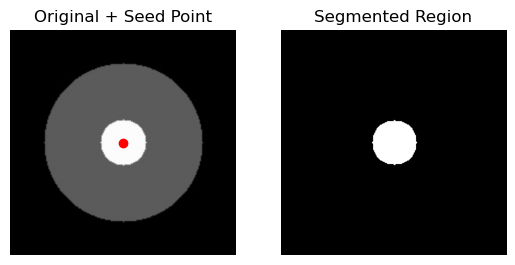

In [23]:
# 4. Display original image and result side-by-side
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.plot(seed[0], seed[1], 'ro')  # Red dot showing seed point
plt.title("Original + Seed Point")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mask, cmap='gray')
plt.title("Segmented Region")
plt.axis("off")

plt.show()

## 19. Implement Region Growing to separate water, vegetation, and land regions from a satellite image.

In [12]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Load satellite image (RGB)
# Replace 'satellite.jpg' with your image path
img = cv2.imread('satelite.png')
img = cv2.resize(img,(400,400))
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Convert to HSV color space (HSV works best for color-based region growing)
img_hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

In [35]:
# 2. Multi-Region Growing Function (using Color Similarity)
def region_growing_color(hsv_img, seed, color_threshold=(15, 40, 40)):
    """
    Grows a region starting from a seed point based on HSV color similarity.
    color_threshold: (H_threshold, S_threshold, V_threshold)
    """
    h, w, _ = hsv_img.shape
    mask = np.zeros((h, w), dtype=np.uint8)
    visited = np.zeros((h, w), dtype=bool)
    
    seed_val = hsv_img[seed[1], seed[0]].astype(int)
    queue = [seed]
    
    while queue:
        x, y = queue.pop(0)
        
        if visited[y, x]:
            continue
        visited[y, x] = True
        
        # Calculate HSV difference from seed pixel
        curr_val = hsv_img[y, x].astype(int)
        h_diff = abs(curr_val[0] - seed_val[0])
        s_diff = abs(curr_val[1] - seed_val[1])
        v_diff = abs(curr_val[2] - seed_val[2])
        
        # Check if difference is within color thresholds
        if h_diff <= color_threshold[0] and s_diff <= color_threshold[1] and v_diff <= color_threshold[2]:
            mask[y, x] = 255
            
            # 4-connected neighbors
            for dx, dy in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
                nx, ny = x + dx, y + dy
                if 0 <= nx < w and 0 <= ny < h and not visited[ny, nx]:
                    queue.append((nx, ny))
                    
    return mask

# 3. Define Seed Points (x, y) for each class
# Note: Adjust these (X, Y) coordinates to match your image feature locations!
seed_water = (75, 180)       # Seed on water body
seed_vegetation = (180,200)  # Seed on green forest/fields
seed_land = (250, 380)       # Seed on bare ground/built-up land

# 4. Grow Regions for each class
mask_water = region_growing_color(img_hsv, seed_water, color_threshold=(15, 60, 60))
mask_veg = region_growing_color(img_hsv, seed_vegetation, color_threshold=(20, 50, 50))
mask_land = region_growing_color(img_hsv, seed_land, color_threshold=(20, 50, 50))

# 5. Create Colored Overlay Map
overlay = np.zeros_like(img_rgb)
overlay[mask_water == 255] = [0, 100, 255]    # Blue for Water
overlay[mask_veg == 255] = [0, 200, 0]        # Green for Vegetation
overlay[mask_land == 255] = [210, 180, 140]   # Brown/Tan for Land

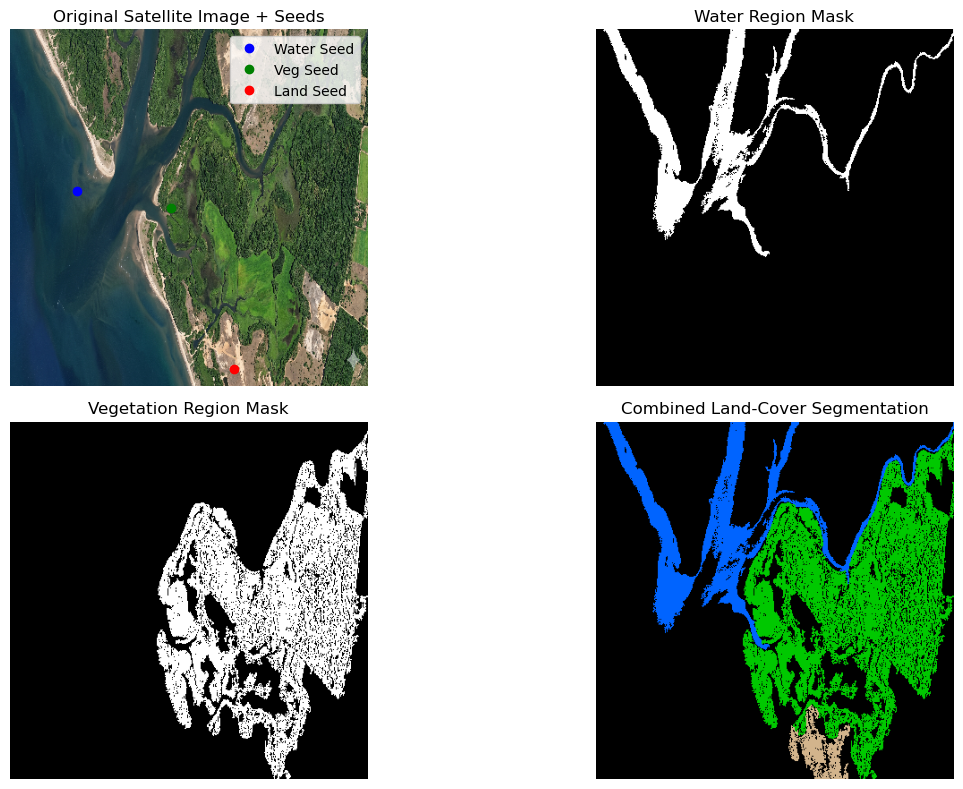

In [36]:
# 6. Display Results
plt.figure(figsize=(14, 8))

plt.subplot(2, 2, 1)
plt.imshow(img_rgb)
plt.plot(seed_water[0], seed_water[1], 'bo', label='Water Seed')
plt.plot(seed_vegetation[0], seed_vegetation[1], 'go', label='Veg Seed')
plt.plot(seed_land[0], seed_land[1], 'ro', label='Land Seed')
plt.title("Original Satellite Image + Seeds")
plt.legend(loc='upper right')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(mask_water, cmap='gray')
plt.title("Water Region Mask")
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(mask_veg, cmap='gray')
plt.title("Vegetation Region Mask")
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(overlay)
plt.title("Combined Land-Cover Segmentation")
plt.axis('off')

plt.tight_layout()
plt.show()

## 20. Implement edge-based image segmentation using the Canny edge detector to identify road boundaries in a road image.

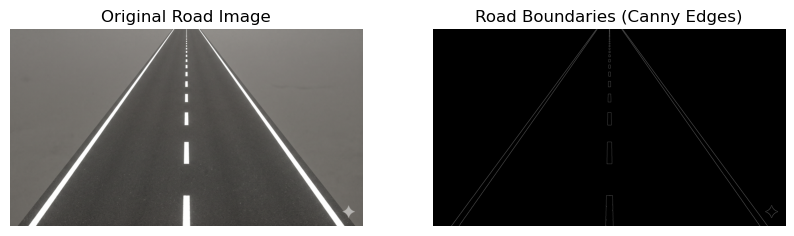

In [46]:
import cv2
import matplotlib.pyplot as plt

# 1. Load your road image
img = cv2.imread('road_edge.png')

# 2. Convert to grayscale & blur to reduce noise
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray, (5, 5), 0)

# 3. Detect edges using Canny
edges = cv2.Canny(blur, 150, 200)

# 4. Display original and detected road boundaries
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Road Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(edges, cmap='gray')
plt.title("Road Boundaries (Canny Edges)")
plt.axis('off')

plt.show()

## 21. Implement edge-based segmentation to separate a foreground object from its background in a real-world photograph

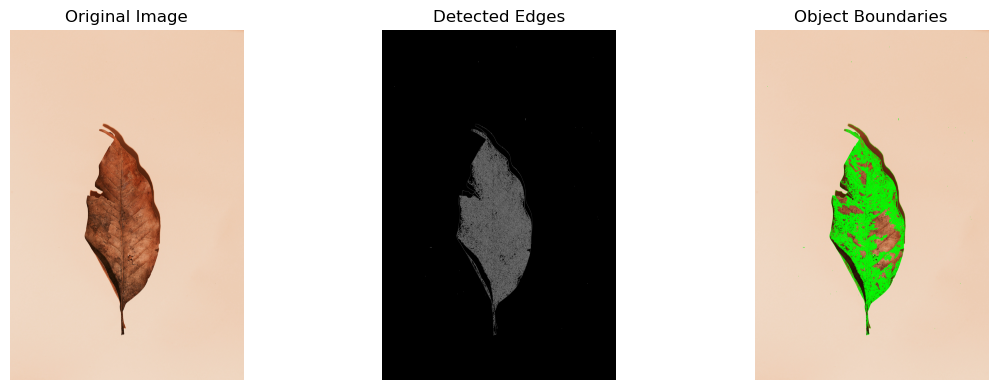

In [58]:
import cv2
import matplotlib.pyplot as plt

# Read image
img = cv2.imread("leaf2.jpg")

if img is None:
    print("Image not found!")
    exit()

# Convert to grayscale
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Reduce noise
blur = cv2.GaussianBlur(gray, (5, 5), 0)

# Detect edges
edges = cv2.Canny(blur, 50, 150)

# Find contours
contours, _ = cv2.findContours(
    edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

# Draw detected object boundaries
result = img.copy()
cv2.drawContours(result, contours, -1, (0, 255, 0), 2)

# Display results
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(edges, cmap="gray")
plt.title("Detected Edges")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Object Boundaries")
plt.axis("off")

plt.tight_layout()
plt.show()

In [62]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Load image & convert to grayscale
img = cv2.imread('leaf2.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# 2. Detect edges using Canny
edges = cv2.Canny(gray, 50, 150)

# 3. Connect broken edges to form a closed shape
kernel = np.ones((5, 5), np.uint8)
closed_edges = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, kernel)

# 4. Find the object boundary and fill it to make a mask
contours, _ = cv2.findContours(closed_edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
mask = np.zeros_like(gray)

if contours:
    largest_contour = max(contours, key=cv2.contourArea)
    cv2.drawContours(mask, [largest_contour], -1, 255, thickness=cv2.FILLED)

# 5. Extract foreground object
foreground = cv2.bitwise_and(img, img, mask=mask)

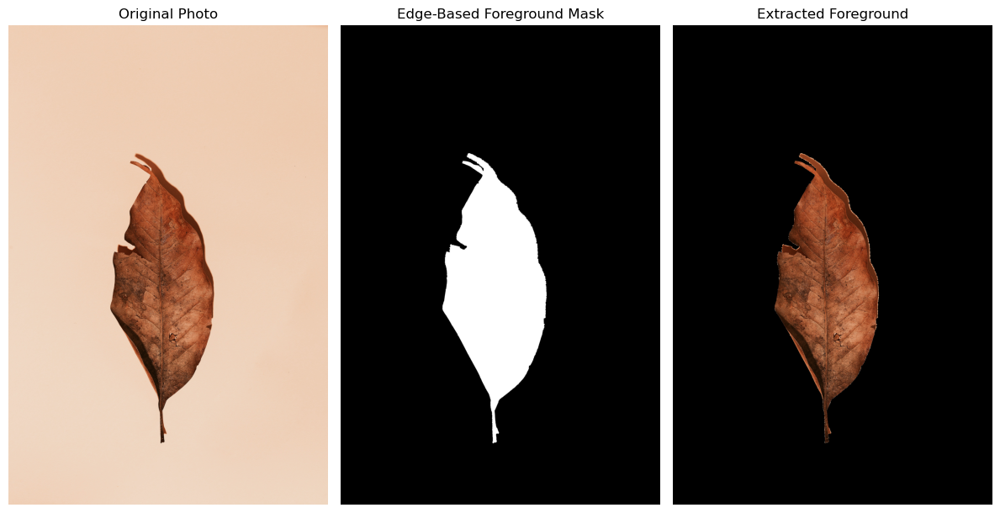

In [63]:
# 6. Display Results
plt.figure(figsize=(12, 6))

plt.subplot(1, 3, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Photo")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(mask, cmap='gray')
plt.title("Edge-Based Foreground Mask")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(cv2.cvtColor(foreground, cv2.COLOR_BGR2RGB))
plt.title("Extracted Foreground")
plt.axis('off')

plt.tight_layout()
plt.show()

## 22. Implement Graph-Cut-based image segmentation to separate a region of interest, such as an organ, from the background in a medical image.

In [36]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Load your medical image
img = cv2.imread('medical3.png') 
img = cv2.resize(img,(400,400))

In [37]:
# 2. Define a bounding box around the organ/region of interest
# Format: (start_x, start_y, width, height)
# Change these values according to where your organ is located in the image
rect = (50,50, 200,300)

# 3. Create mask and temporary models required by GrabCut
mask = np.zeros(img.shape[:2], np.uint8)
bgd_model = np.zeros((1, 65), np.float64)
fgd_model = np.zeros((1, 65), np.float64)

# 4. Apply Graph-Cut (GrabCut) algorithm
# Runs for 5 iterations using the bounding box setup
cv2.grabCut(img, mask, rect, bgd_model, fgd_model, 5, cv2.GC_INIT_WITH_RECT)

# 5. Extract foreground (Values 1 and 3 in the mask belong to foreground)
output_mask = np.where((mask == 1) | (mask == 3), 1, 0).astype('uint8')
foreground = img * output_mask[:, :, np.newaxis]

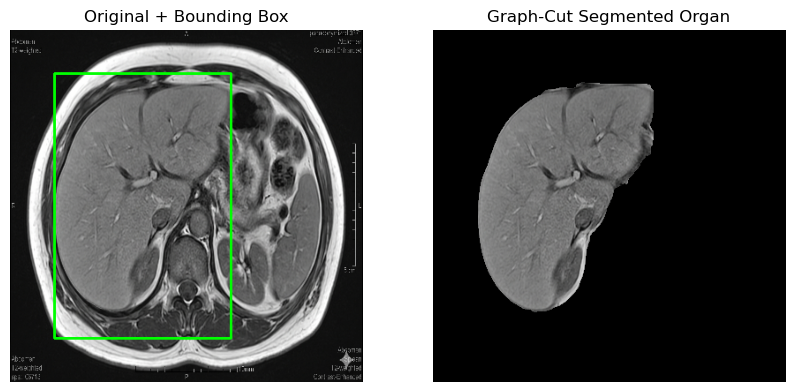

In [38]:
# 6. Display original image with rectangle and extracted region
plt.figure(figsize=(10, 5))

# Plot 1: Bounding Box Selection
img_with_rect = img.copy()
cv2.rectangle(img_with_rect, (rect[0], rect[1]), (rect[0]+rect[2], rect[1]+rect[3]), (0, 255, 0), 2)
plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img_with_rect, cv2.COLOR_BGR2RGB))
plt.title("Original + Bounding Box")
plt.axis('off')

# Plot 2: Extracted Organ / Foreground
plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(foreground, cv2.COLOR_BGR2RGB))
plt.title("Graph-Cut Segmented Organ")
plt.axis('off')

plt.show()

## 23. Implement Graph Cut to remove the background from a photograph and extract the required foreground object.

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Load your image
# Replace 'your_image.jpg' with your actual image path
img = cv2.imread('bike.png')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

In [3]:
# 2. Automatically set a bounding box around the center (or manually edit coordinates)
# Format: (start_x, start_y, width, height)
h, w = img.shape[:2]
rect = (int(w * 0.1), int(h * 0.1), int(w * 0.8), int(h * 0.8))

# 3. Initialize Graph-Cut structures
mask = np.zeros((h, w), np.uint8)
bgd_model = np.zeros((1, 65), np.float64)
fgd_model = np.zeros((1, 65), np.float64)

# 4. Run Graph-Cut (GrabCut) for 5 iterations
cv2.grabCut(img, mask, rect, bgd_model, fgd_model, 5, cv2.GC_INIT_WITH_RECT)

# 5. Extract Foreground (Values 1 and 3 belong to the object)
output_mask = np.where((mask == 1) | (mask == 3), 1, 0).astype('uint8')
foreground = img_rgb * output_mask[:, :, np.newaxis]

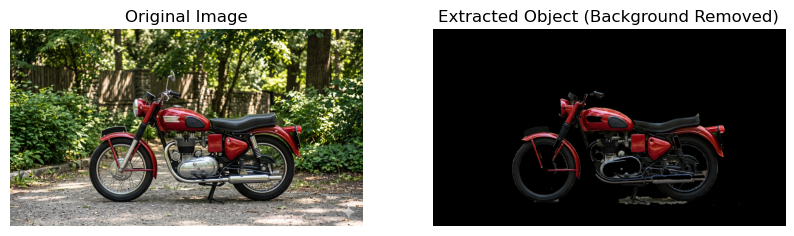

In [4]:
# 6. Display Results
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(foreground)
plt.title("Extracted Object (Background Removed)")
plt.axis('off')

plt.show()

## 24. Implement Mean-Shift segmentation to divide a natural scene image into meaningful regions based on color and spatial information.

In [27]:
import cv2
import matplotlib.pyplot as plt

# Read image
img = cv2.imread("nature.png")
img = cv2.resize(img,(400,400))

if img is None:
    print("Image not found!")
    exit()

In [28]:
# Apply Mean-Shift segmentation 
result = cv2.pyrMeanShiftFiltering(img,sp=50,sr=50,maxLevel=1)

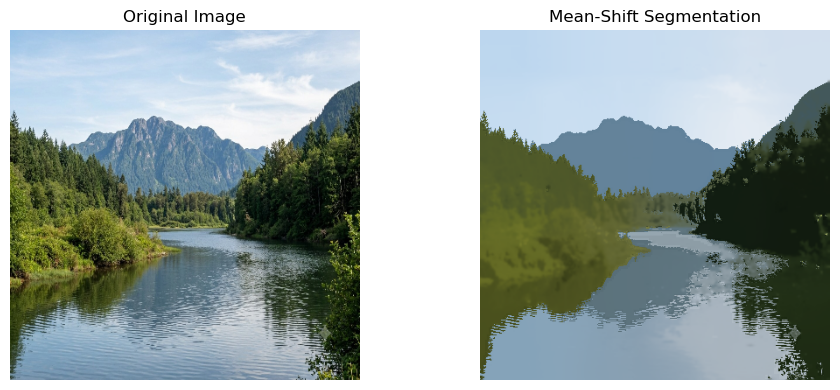

In [29]:
# Display images
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Mean-Shift Segmentation")
plt.axis("off")

plt.tight_layout()
plt.show()

## 25. Implement Markov Random Field (MRF)-based image segmentation to classify pixels into different regions in a noisy image and compare the result with basic segmentation.

In [30]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read grayscale image
img = cv2.imread("nature.png", 0)

if img is None:
    print("Image not found!")
    exit()

noisy = img 

In [34]:
# Basic segmentation
_, basic_seg = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# MRF-like segmentation using smoothing
smooth = cv2.medianBlur(noisy, 5)
_, mrf_result = cv2.threshold(smooth, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

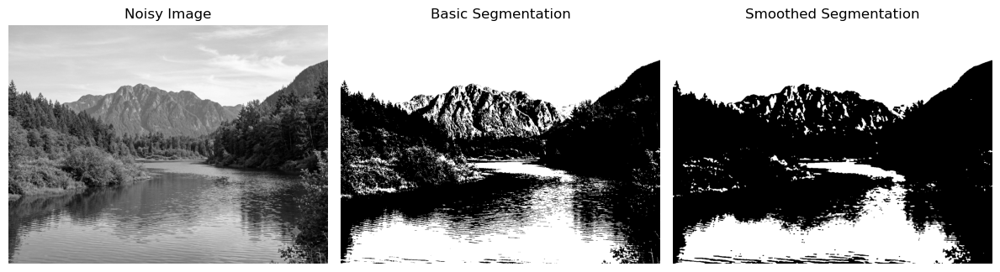

In [36]:
# Display results
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(noisy, cmap="gray")
plt.title("Noisy Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(basic, cmap="gray")
plt.title("Basic Segmentation")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(mrf_result, cmap="gray")
plt.title("Smoothed Segmentation")
plt.axis("off")

plt.tight_layout()
plt.show()

## 26. Implement texture-based image segmentation using Gabor-filter or DWT-based features to separate regions with different textures, such as grass, road, and building surfaces.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read image
img = cv2.imread("road2.jpg", 0)

if img is None:
    print("Image not found!")
    exit()
img  = cv2.resize(img,(600,400))

In [4]:
# Apply Gabor filter
kernel = cv2.getGaborKernel((5,5), 10, 180, 5, 1, 0)
filtered = cv2.filter2D(img, cv2.CV_32F, kernel)

# Normalize filtered image
filtered = cv2.normalize(filtered, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

# Segment into two texture regions
_, segmented = cv2.threshold(filtered, 127, 255, cv2.THRESH_BINARY)

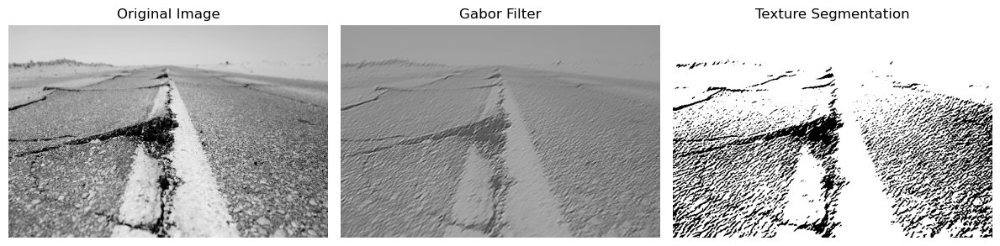

In [5]:
# Display results
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(filtered, cmap="gray")
plt.title("Gabor Filter")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(segmented, cmap="gray")
plt.title("Texture Segmentation")
plt.axis("off")

plt.tight_layout()
plt.show()

## 27. Implement an object detection system to detect and count cars, motorcycles, and buses in a traffic image or video.

In [87]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

# Read traffic image
img = cv2.imread("traffic2.png")

if img is None:
    print("Image not found!")
    exit()

In [88]:
# Load pre-trained YOLO model
model = YOLO()

# Detect objects
results = model(img)

# Vehicle classes in COCO dataset
vehicles = {2: "Car",3: "Motorcycle",5: "Bus"}
counts = {"Car": 0, "Motorcycle": 0, "Bus": 0}

# Draw boxes and count vehicles
for box in results[0].boxes:
    class_id = int(box.cls[0])

    if class_id in vehicles:
        name = vehicles[class_id]
        counts[name] += 1

        x1, y1, x2, y2 = map(int, box.xyxy[0])
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(img, name, (x1, y1 - 10),cv2.FONT_HERSHEY_SIMPLEX, 0.6,(0, 255, 0), 2)


0: 384x640 5 persons, 15 cars, 4 motorcycles, 5 buss, 1 truck, 192.0ms
Speed: 5.9ms preprocess, 192.0ms inference, 3.3ms postprocess per image at shape (1, 3, 384, 640)


Cars: 15
Motorcycles: 4
Buses: 5


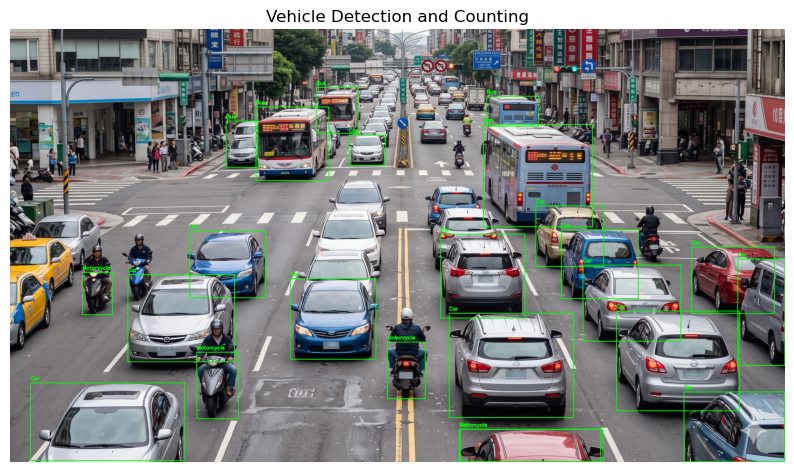

In [89]:
# Display vehicle counts
print("Cars:", counts["Car"])
print("Motorcycles:", counts["Motorcycle"])
print("Buses:", counts["Bus"])

# Display result
plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Vehicle Detection and Counting")
plt.axis("off")
plt.show()

## 28. Develop an object detection and recognition system to identify garbage and classify it into categories such as plastic, paper, metal, glass, and organic waste.


0: 384x640 1 bottle, 1 cup, 1 bowl, 3 bananas, 1 orange, 98.8ms
Speed: 4.9ms preprocess, 98.8ms inference, 2.4ms postprocess per image at shape (1, 3, 384, 640)


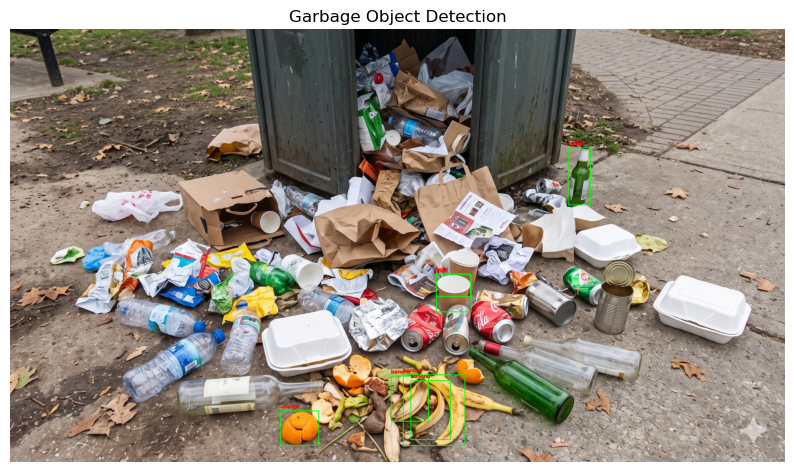

In [17]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

# Load pre-trained YOLO model
model = YOLO("yolov8n.pt")

# Read garbage image
img = cv2.imread("garbage.png")

if img is None:
    print("Image not found!")
    exit()

# Detect objects
results = model(img)

# Display detected objects
for box in results[0].boxes:
    class_id = int(box.cls[0])
    name = model.names[class_id]

    x1, y1, x2, y2 = map(int, box.xyxy[0])

    cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
    cv2.putText(img, name, (x1, y1 - 10),cv2.FONT_HERSHEY_SIMPLEX, 0.6,(0,0,255), 2)

# Show result
plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Garbage Object Detection")
plt.axis("off")
plt.show()

## 29. Develop an object detection and recognition system to identify different products on a store shelf and display their corresponding class labels.


0: 384x640 14 bottles, 13 potted plants, 1 book, 1 vase, 90.6ms
Speed: 4.6ms preprocess, 90.6ms inference, 2.9ms postprocess per image at shape (1, 3, 384, 640)


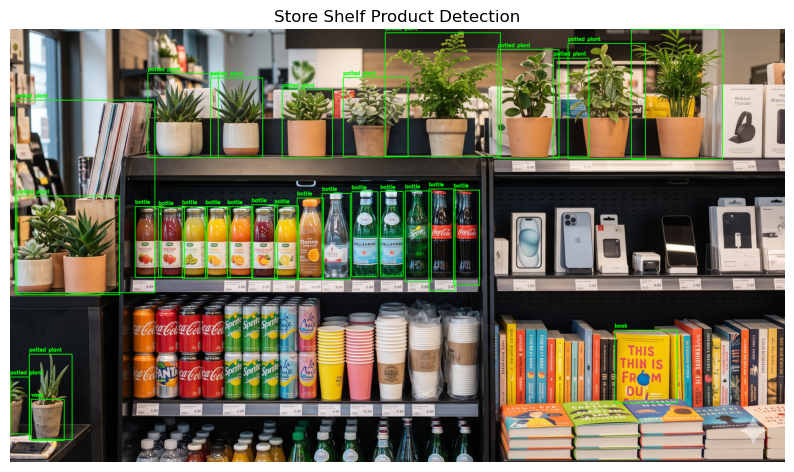

In [20]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

# Load YOLO model
model = YOLO("yolov8n.pt")

# Read shelf image
img = cv2.imread("shelf.png")

if img is None:
    print("Image not found!")
    exit()

# Detect objects
results = model(img)

# Draw bounding boxes and labels
for box in results[0].boxes:
    class_id = int(box.cls[0])
    label = model.names[class_id]

    x1, y1, x2, y2 = map(int, box.xyxy[0])

    cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
    cv2.putText(img, label, (x1, y1 - 10),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6,
                (0, 255, 0), 2)

# Display result
plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Store Shelf Product Detection")
plt.axis("off")
plt.show()

## 30. Develop a real-time object detection and recognition system for smart-city surveillance that detects predefined objects such as people and vehicles, draws bounding boxes around them, and displays their confidence scores.


0: 384x640 6 persons, 24 cars, 5 motorcycles, 5 buss, 1 truck, 131.1ms
Speed: 6.2ms preprocess, 131.1ms inference, 2.3ms postprocess per image at shape (1, 3, 384, 640)


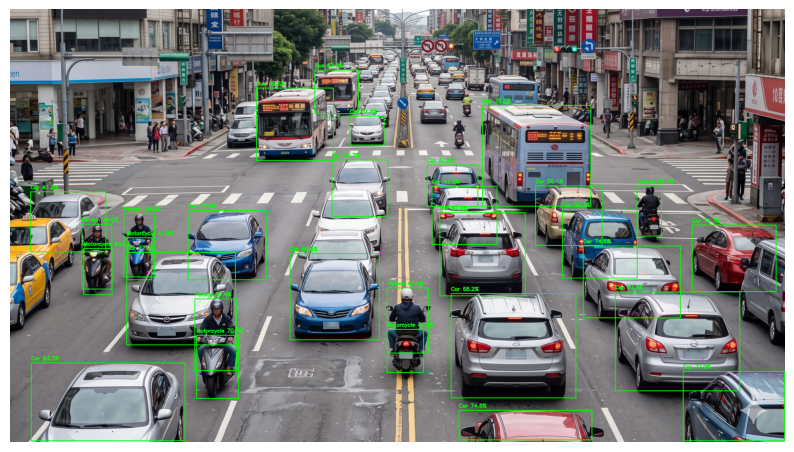

In [2]:
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

model = YOLO('yolov8n.pt')
SURVEILLANCE_CLASSES = {0: "Person", 2: "Car", 3: "Motorcycle", 5: "Bus", 7: "Truck"}

# Process a single frame/image directly for testing
img = cv2.imread('traffic2.png') # or read a frame from cv2.VideoCapture
results = model(img)

for box in results[0].boxes:
    class_id = int(box.cls[0])
    conf = float(box.conf[0])
    
    if class_id in SURVEILLANCE_CLASSES and conf > 0.4:
        x1, y1, x2, y2 = map(int, box.xyxy[0])
        label_text = f"{SURVEILLANCE_CLASSES[class_id]} {conf*100:.1f}%"
        
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(img, label_text, (x1, y1 - 10),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)

# Display safely in Notebooks
plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()


0: 640x384 2 persons, 3 cars, 2 motorcycles, 2 trucks, 74.2ms
Speed: 5.2ms preprocess, 74.2ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 384)


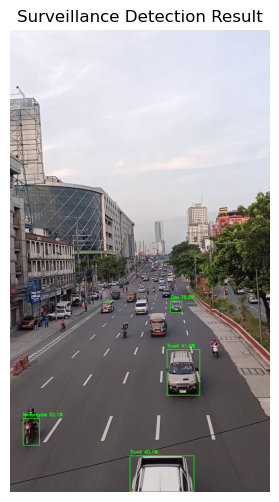

In [5]:
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

model = YOLO('yolov8n.pt')
SURVEILLANCE_CLASSES = {0: "Person", 2: "Car", 3: "Motorcycle", 5: "Bus", 7: "Truck"}

# Read first valid frame from your video file
cap = cv2.VideoCapture('cctv.mp4')
ret, frame = cap.read()
cap.release()

if ret:
    results = model(frame)

    for box in results[0].boxes:
        class_id = int(box.cls[0])
        conf = float(box.conf[0])
        
        if class_id in SURVEILLANCE_CLASSES and conf > 0.4:
            x1, y1, x2, y2 = map(int, box.xyxy[0])
            label_text = f"{SURVEILLANCE_CLASSES[class_id]} {conf * 100:.1f}%"
            
            cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 2)
            cv2.putText(frame, label_text, (x1, y1 - 10),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)

    plt.figure(figsize=(10, 6))
    plt.imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    plt.title("Surveillance Detection Result")
    plt.axis('off')
    plt.show()

In [14]:
import cv2
from ultralytics import YOLO

model = YOLO("yolov8n.pt")
cap = cv2.VideoCapture("cctv.mp4")

classes = ["person", "car", "motorcycle", "bus", "truck", "bicycle"]

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break

    # Detect objects
    results = model(frame, verbose=False)[0]

    for box in results.boxes:
        label = model.names[int(box.cls[0])]
        conf = float(box.conf[0])

        if label in classes and conf > 0.4:
            x1, y1, x2, y2 = map(int, box.xyxy[0])
            
            # Draw box and label
            cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 2)
            cv2.putText(frame, f"{label}: {conf:.2f}", (x1, y1 - 10),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)

    # Resize and display
    cv2.imshow("CCTV Detection", cv2.resize(frame, (800, 700)))
    if cv2.waitKey(1) & 0xFF == ord("q"):
        break

cap.release()
cv2.destroyAllWindows()